# 5-ASC — Acoustic Scene Classification (ASC)
### Demo: Pretrained YAMNet embeddings (clip-mean) + Logistic Regression

### AIML ZG527: Audio Analysis
**Authored by:** Seetha Parameswaran, BITS Pilani WILP
### Learning Objectives
- Reuse YAMNet embeddings, mean-pooled over the whole clip
- Train a linear classifier to label the recording environment
- Evaluate scene classification on TAU Urban Acoustic Scenes 2019
---
### Setup and Import Libraries

**Task (ASC):** assign **one** label describing the **environment** a recording was made in
(park, metro, office...). The scene is a **texture** of many overlapping sounds, not one event.

**Approach:** same frozen **YAMNet** backbone as 5-ESC, but embeddings are **mean-pooled over
the whole clip** so the vector captures the overall soundscape statistics (global pooling).
A linear head is trained on top. CPU only, nothing saved to disk.

---
**Requirements:**
```
pip install tensorflow tensorflow_hub librosa resampy scikit-learn matplotlib
```

---
### Dataset: TAU Urban Acoustic Scenes 2019 (subset)
Download a few audio parts + meta from Zenodo (record 2589280); parts are scene-split,
so pull several to get multiple scenes. Files resolved via `meta.csv`.

```
mkdir -p ~/datasets/TAU2019 && cd ~/datasets/TAU2019

wget "https://zenodo.org/records/2589280/files/TAU-urban-acoustic-scenes-2019-development.meta.zip?download=1" -O meta.zip

wget "https://zenodo.org/records/2589280/files/TAU-urban-acoustic-scenes-2019-development.audio.1.zip?download=1" -O audio.1.zip

wget "https://zenodo.org/records/2589280/files/TAU-urban-acoustic-scenes-2019-development.audio.1.zip?download=1" -O audio.5.zip

wget "https://zenodo.org/records/2589280/files/TAU-urban-acoustic-scenes-2019-development.audio.1.zip?download=1" -O audio.7.zip

wget "https://zenodo.org/records/2589280/files/TAU-urban-acoustic-scenes-2019-development.audio.1.zip?download=1" -O audio.11.zip

wget "https://zenodo.org/records/2589280/files/TAU-urban-acoustic-scenes-2019-development.audio.1.zip?download=1" -O audio.13.zip

unzip -q meta.zip && unzip -q audio.1.zip && unzip -q audio.5.zip && unzip -q audio.7.zip && unzip -q audio.11.zip && unzip -q audio.13.zip
```

In [7]:
import os, glob
import numpy as np
import pandas as pd
import librosa
import tensorflow_hub as hub
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
np.random.seed(0)

## 1. Configuration
Assumed layout of the hosted subset (edit `ASC_ROOT` after downloading):
```
ASC_ROOT/
  park/         clip001.wav ...
  metro/        ...
  public_square/...
  street_traffic/...
  airport/      ...
```
One folder per scene, ~100 clips each is plenty for a demo.

In [10]:
import glob

META_CSV = '/home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/TAU2019/meta/TAU-urban-acoustic-scenes-2019-development/meta.csv'
TAU_ROOT = '/home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/TAU2019'

SR = 16000
MAX_PER_CLASS = 100
TEST_SIZE = 0.25
assert os.path.exists(META_CSV), f'{META_CSV} not found'

# every downloaded/unzipped part dir
audio_dirs = sorted(glob.glob(os.path.join(TAU_ROOT, 'audio.*',
                    'TAU-urban-acoustic-scenes-2019-development')))
print('part dirs found:', len(audio_dirs))


## Index the subset from meta.csv
meta = pd.read_csv(META_CSV, sep='\t')   # filename, scene_label, identifier, source_label

def resolve(fn):
    for d in audio_dirs:
        p = os.path.join(d, fn)
        if os.path.exists(p):
            return p
    return None

meta['path'] = meta['filename'].apply(resolve)
meta = meta[meta['path'].notna()].reset_index(drop=True)   # keep only present files
assert len(meta) > 0, 'no audio found yet'

meta = (meta.groupby('scene_label', group_keys=False)
            .apply(lambda g: g.sample(min(len(g), MAX_PER_CLASS), random_state=0))
            .reset_index(drop=True))

files  = meta['path'].tolist()
labels = meta['scene_label'].to_numpy()
SCENES = sorted(meta['scene_label'].unique())
print(f'Scenes ({len(SCENES)}):', SCENES)
print('Total clips available:', len(files))

part dirs found: 6
Scenes (7): ['airport', 'bus', 'metro', 'metro_station', 'park', 'public_square', 'shopping_mall']
Total clips available: 700


In [11]:
import glob, os, pandas as pd
meta = pd.read_csv(META_CSV, sep='\t')
audio_dirs = sorted(glob.glob(os.path.join(TAU_ROOT, 'audio.*',
                    'TAU-urban-acoustic-scenes-2019-development')))
present = {f for d in audio_dirs for f in
           [os.path.relpath(p, d) for p in glob.glob(os.path.join(d,'audio','*.wav'))]}
sub = meta[meta['filename'].isin(present)]
print(sub['scene_label'].value_counts())

airport          1388
public_square     746
metro             746
metro_station     538
shopping_mall     382
park              260
bus               104
Name: scene_label, dtype: int64


## 2. Load YAMNet (pretrained, frozen)

In [4]:
yamnet = hub.load('https://tfhub.dev/google/yamnet/1')
print('YAMNet loaded.')

2026-07-01 19:46:17.548518: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcuda.so.1'; dlerror: libcuda.so.1: cannot open shared object file: No such file or directory
2026-07-01 19:46:17.548567: W tensorflow/stream_executor/cuda/cuda_driver.cc:269] failed call to cuInit: UNKNOWN ERROR (303)
2026-07-01 19:46:17.548592: I tensorflow/stream_executor/cuda/cuda_diagnostics.cc:156] kernel driver does not appear to be running on this host (seetha-HP-348-G4): /proc/driver/nvidia/version does not exist
2026-07-01 19:46:17.548800: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


YAMNet loaded.


## 3. Clip -> YAMNet embedding (mean over all frames)
Mean-pooling across the whole clip is the key ASC choice: it summarises the scene *texture*.

In [12]:
def clip_embedding(path):
    wav, _ = librosa.load(path, sr=SR, mono=True)
    if wav.size < SR:
        wav = np.pad(wav, (0, SR - wav.size))
    _, emb, _ = yamnet(wav.astype(np.float32))   # (frames, 1024)
    return emb.numpy().mean(axis=0)              # (1024,)

X, y = [], []
print('Extracting embeddings (CPU)...')
for i, (f, lab) in enumerate(zip(files, labels)):
    try:
        X.append(clip_embedding(f)); y.append(lab)
    except Exception as e:
        print('skip', f, e)
    if (i+1) % 50 == 0:
        print(f'  {i+1}/{len(files)} clips embedded...')
X = np.vstack(X); y = np.array(y)
print('Feature matrix:', X.shape)

Extracting embeddings (CPU)...
  50/700 clips embedded...
  100/700 clips embedded...
  150/700 clips embedded...
  200/700 clips embedded...
  250/700 clips embedded...
  300/700 clips embedded...
  350/700 clips embedded...
  400/700 clips embedded...
  450/700 clips embedded...
  500/700 clips embedded...
  550/700 clips embedded...
  600/700 clips embedded...
  650/700 clips embedded...
  700/700 clips embedded...
Feature matrix: (700, 1024)


## 4. Train / test split and linear head

In [13]:
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=0)

clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
clf.fit(X_tr, y_tr)
print('Head trained on', X_tr.shape[0], 'clips.')

Head trained on 525 clips.


## 5. Evaluate

In [14]:
y_pred = clf.predict(X_te)
acc = accuracy_score(y_te, y_pred)
print(f'Test accuracy: {acc:.3f}\n')
print(classification_report(y_te, y_pred))

Test accuracy: 0.691

               precision    recall  f1-score   support

      airport       0.65      0.60      0.63        25
          bus       0.74      0.80      0.77        25
        metro       0.65      0.68      0.67        25
metro_station       0.47      0.28      0.35        25
         park       0.96      1.00      0.98        25
public_square       0.81      0.88      0.85        25
shopping_mall       0.48      0.60      0.54        25

     accuracy                           0.69       175
    macro avg       0.68      0.69      0.68       175
 weighted avg       0.68      0.69      0.68       175



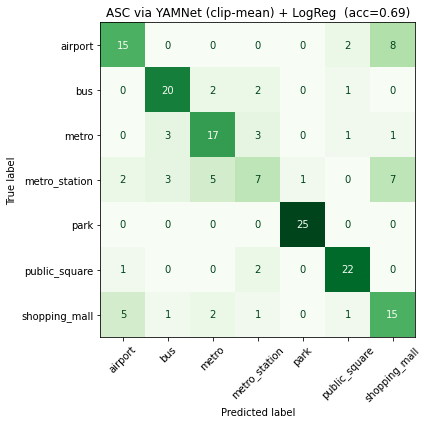

In [15]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_te, y_pred, labels=SCENES, xticks_rotation=45,
    cmap='Greens', ax=ax, colorbar=False)
ax.set_title(f'ASC via YAMNet (clip-mean) + LogReg  (acc={acc:.2f})')
plt.tight_layout(); plt.show()

## 6. Example predictions (inline audio)

In [16]:
from IPython.display import Audio, display
idx = np.random.RandomState(1).choice(len(X_te), size=min(3, len(X_te)), replace=False)
# rebuild file list aligned to the split for playback
# (re-embed the picked test clips is unnecessary; just show a few raw test files)
sample_files = np.random.RandomState(2).choice(files, size=3, replace=False)
for f in sample_files:
    pred = clf.predict(clip_embedding(f).reshape(1, -1))[0]
    true = os.path.basename(os.path.dirname(f))
    wav, _ = librosa.load(f, sr=SR, mono=True)
    print(f'TRUE: {true:<16}  PRED: {pred}')
    display(Audio(wav, rate=SR))

TRUE: audio             PRED: park


TRUE: audio             PRED: metro_station


TRUE: audio             PRED: metro



## Summary
In this demo, you saw:
1. **Scene = texture**: mean-pooling the whole clip captures the soundscape, not one event
2. **Evaluation**: accuracy + confusion matrix across scenes
### Key Takeaways

- **ESC vs ASC:** identical YAMNet front-end; the difference is that ASC mean-pools the whole
  clip to capture the **scene texture** rather than one dominant event.
- Confusions cluster among acoustically similar environments (e.g. *metro* vs *tram*,
  *public_square* vs *street_traffic*).
- **Device mismatch** (train on one mic, test on another) is the classic ASC failure mode; if
  your subset carries a device tag, split train/test by device to see the drop.
- Next: **5-SED** reuses YAMNet but reads its **per-frame** scores to get *what + when*.